In [1]:
import pandas as pd
import psycopg
from getpass import getpass

senha = getpass("Digite a senha do usuario postgres: ")

conexao = psycopg.connect(
    host="localhost",
    port=5432,
    dbname="bi_comercial",
    user="postgres",
    password=senha
)

print("Conexao com PostgreSQL realizada com sucesso!")

Digite a senha do usuario postgres:  ········


Conexao com PostgreSQL realizada com sucesso!


In [3]:
consulta = """
SELECT
    COUNT(*) AS total_itens,
    COUNT(DISTINCT id_venda) AS total_pedidos,
    COUNT(DISTINCT id_cliente) AS clientes_compradores
FROM fato_vendas;
"""

df_resumo = pd.read_sql_query(consulta, conexao)
df_resumo

C:\Users\gusta\AppData\Local\Temp\ipykernel_13544\861836178.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_resumo = pd.read_sql_query(consulta, conexao)


,total_itens,total_pedidos,clientes_compradores
0,11091,6000,300


In [4]:
consulta_mensal = """
SELECT
    d.ano,
    d.mes,
    d.nome_mes,
    COUNT(DISTINCT f.id_venda) AS pedidos,
    SUM(f.quantidade) AS unidades_vendidas,
    ROUND(SUM(f.receita_liquida), 2) AS receita_liquida,
    ROUND(SUM(f.custo_total), 2) AS custo_total,
    ROUND(
        SUM(f.receita_liquida) - SUM(f.custo_total),
        2
    ) AS margem_bruta
FROM fato_vendas f
JOIN dim_data d
    ON f.id_data = d.id_data
GROUP BY
    d.ano,
    d.mes,
    d.nome_mes
ORDER BY
    d.ano,
    d.mes;
"""

df_mensal = pd.read_sql_query(
    consulta_mensal,
    conexao
)

df_mensal

C:\Users\gusta\AppData\Local\Temp\ipykernel_13544\2935963431.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_mensal = pd.read_sql_query(


,ano,mes,nome_mes,pedidos,unidades_vendidas,receita_liquida,custo_total,margem_bruta
0,2024,1,Janeiro,88,257,19614.63,9096.38,10518.25
1,2024,2,Fevereiro,76,226,18381.79,8597.24,9784.55
2,2024,3,Marco,105,298,22660.51,10606.92,12053.59
3,2024,4,Abril,120,357,28107.71,12881.66,15226.05
4,2024,5,Maio,170,487,38313.11,18050.77,20262.34
5,2024,6,Junho,164,443,34275.64,16045.71,18229.93
6,2024,7,Julho,177,503,38583.66,18148.29,20435.37
7,2024,8,Agosto,173,535,40922.20,18894.27,22027.93
8,2024,9,Setembro,146,432,34291.95,16096.40,18195.55
9,2024,10,Outubro,226,671,52953.67,24850.42,28103.25


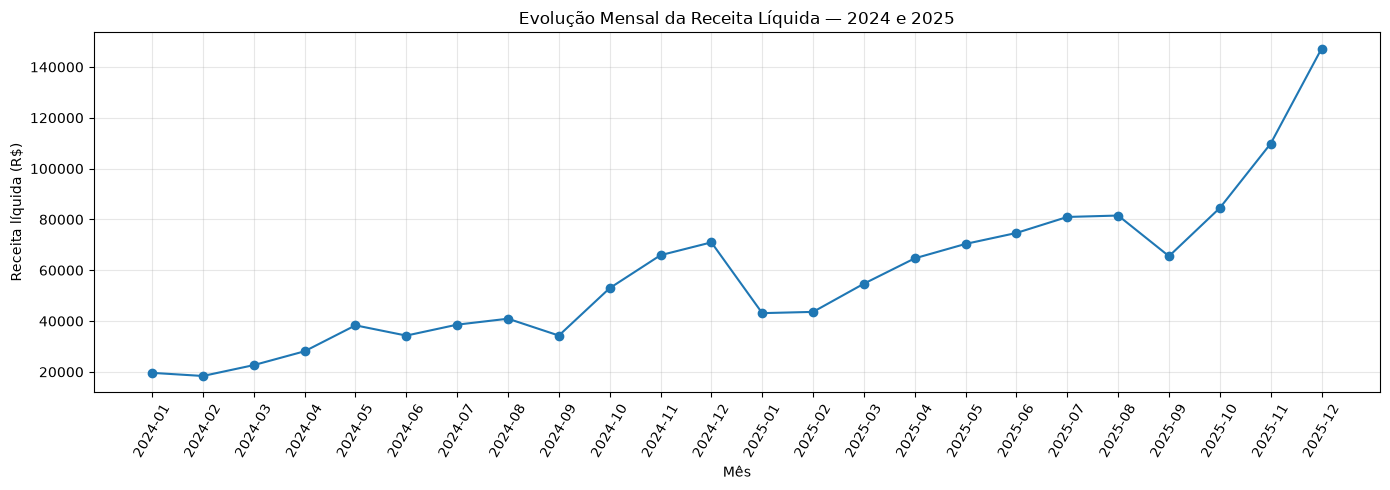

In [6]:
import matplotlib.pyplot as plt

df_mensal["periodo"] = (
    df_mensal["ano"].astype(str)
    + "-"
    + df_mensal["mes"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 5))
plt.plot(
    df_mensal["periodo"],
    df_mensal["receita_liquida"],
    marker="o"
)

plt.title("Evolução Mensal da Receita Líquida — 2024 e 2025")
plt.xlabel("Mês")
plt.ylabel("Receita líquida (R$)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
consulta_recencia = """
SELECT
    c.id_cliente,
    c.nome_cliente,
    c.status_cliente,
    MAX(d.data_completa) AS ultima_compra,
    (SELECT MAX(data_completa) FROM dim_data) AS data_referencia,
    (SELECT MAX(data_completa) FROM dim_data)
        - MAX(d.data_completa) AS dias_sem_comprar
FROM fato_vendas f
JOIN dim_cliente c
    ON f.id_cliente = c.id_cliente
JOIN dim_data d
    ON f.id_data = d.id_data
GROUP BY
    c.id_cliente,
    c.nome_cliente,
    c.status_cliente
ORDER BY dias_sem_comprar DESC;
"""

df_recencia = pd.read_sql_query(
    consulta_recencia,
    conexao
)

df_recencia.head(10)

C:\Users\gusta\AppData\Local\Temp\ipykernel_13544\3438162972.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_recencia = pd.read_sql_query(


,id_cliente,nome_cliente,status_cliente,ultima_compra,data_referencia,dias_sem_comprar
0,51,Paula Dias,ATIVO,2024-06-06,2025-12-31,573
1,260,Natalia Santos,ATIVO,2024-07-13,2025-12-31,536
2,144,Eduarda Santos,ATIVO,2024-07-13,2025-12-31,536
3,127,Felipe Lima,ATIVO,2024-07-29,2025-12-31,520
4,259,Vanessa Barbosa,ATIVO,2024-08-07,2025-12-31,511
5,39,Joao Ferreira,INATIVO,2024-08-08,2025-12-31,510
6,291,Carla Araujo,ATIVO,2024-08-10,2025-12-31,508
7,27,Julia Pereira,INATIVO,2024-08-17,2025-12-31,501
8,192,Camila Ferreira,ATIVO,2024-08-20,2025-12-31,498
9,62,Thiago Pereira,INATIVO,2024-09-26,2025-12-31,461


In [8]:
df_recencia["ultima_compra"] = pd.to_datetime(
    df_recencia["ultima_compra"]
)

df_recencia["data_referencia"] = pd.to_datetime(
    df_recencia["data_referencia"]
)

df_recencia["situacao_reativacao"] = df_recencia[
    "dias_sem_comprar"
].apply(
    lambda dias: (
        "Candidato à reativação"
        if dias >= 90
        else "Compra recente"
    )
)

df_recencia["situacao_reativacao"].value_counts()

situacao_reativacao
Compra recente            164
Candidato à reativação    136
Name: count, dtype: int64

In [9]:
total_compradores = len(df_recencia)

total_reativacao = (
    df_recencia["situacao_reativacao"]
    == "Candidato à reativação"
).sum()

percentual_reativacao = (
    total_reativacao / total_compradores
) * 100

print(f"Clientes compradores: {total_compradores}")
print(f"Candidatos à reativação: {total_reativacao}")
print(f"Percentual: {percentual_reativacao:.1f}%")

df_recencia[
    df_recencia["situacao_reativacao"]
    == "Candidato à reativação"
].head(10)

Clientes compradores: 300
Candidatos à reativação: 136
Percentual: 45.3%


,id_cliente,nome_cliente,status_cliente,ultima_compra,data_referencia,dias_sem_comprar,situacao_reativacao
0,51,Paula Dias,ATIVO,2024-06-06,2025-12-31,573,Candidato à reativação
1,260,Natalia Santos,ATIVO,2024-07-13,2025-12-31,536,Candidato à reativação
2,144,Eduarda Santos,ATIVO,2024-07-13,2025-12-31,536,Candidato à reativação
3,127,Felipe Lima,ATIVO,2024-07-29,2025-12-31,520,Candidato à reativação
4,259,Vanessa Barbosa,ATIVO,2024-08-07,2025-12-31,511,Candidato à reativação
5,39,Joao Ferreira,INATIVO,2024-08-08,2025-12-31,510,Candidato à reativação
6,291,Carla Araujo,ATIVO,2024-08-10,2025-12-31,508,Candidato à reativação
7,27,Julia Pereira,INATIVO,2024-08-17,2025-12-31,501,Candidato à reativação
8,192,Camila Ferreira,ATIVO,2024-08-20,2025-12-31,498,Candidato à reativação
9,62,Thiago Pereira,INATIVO,2024-09-26,2025-12-31,461,Candidato à reativação


In [10]:
df_recencia["faixa_recencia"] = pd.cut(
    df_recencia["dias_sem_comprar"],
    bins=[-1, 30, 60, 90, 180, 365, float("inf")],
    labels=[
        "Até 30 dias",
        "31 a 60 dias",
        "61 a 90 dias",
        "91 a 180 dias",
        "181 a 365 dias",
        "Mais de 365 dias",
    ]
)

resumo_recencia = (
    df_recencia
    .groupby("faixa_recencia", observed=False)
    .size()
    .reset_index(name="quantidade_clientes")
)

resumo_recencia

,faixa_recencia,quantidade_clientes
0,Até 30 dias,135
1,31 a 60 dias,21
2,61 a 90 dias,9
3,91 a 180 dias,49
4,181 a 365 dias,57
5,Mais de 365 dias,29


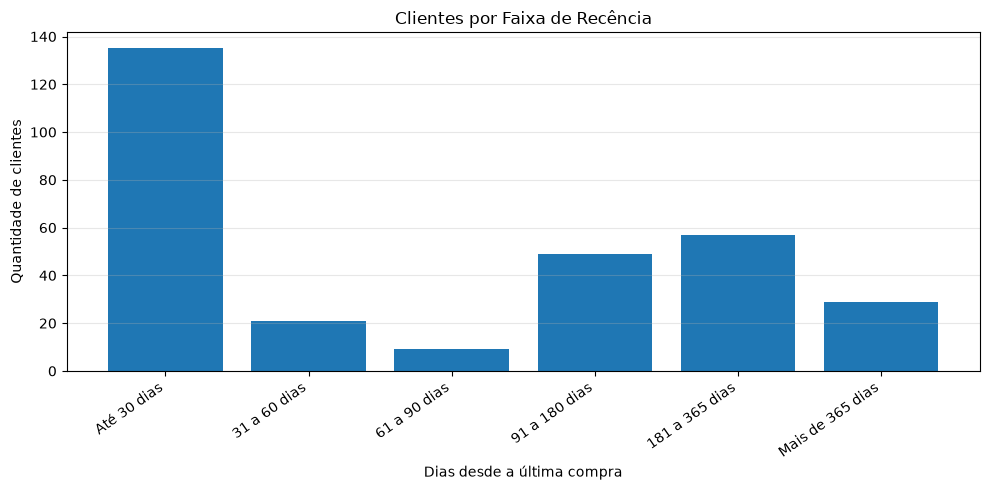

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    resumo_recencia["faixa_recencia"].astype(str),
    resumo_recencia["quantidade_clientes"]
)

plt.title("Clientes por Faixa de Recência")
plt.xlabel("Dias desde a última compra")
plt.ylabel("Quantidade de clientes")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path

pasta_saida = Path("../dados/tratados")
pasta_saida.mkdir(parents=True, exist_ok=True)

df_mensal.to_csv(
    pasta_saida / "analise_mensal.csv",
    index=False,
    encoding="utf-8-sig"
)

df_recencia.to_csv(
    pasta_saida / "analise_recencia_clientes.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo_recencia.to_csv(
    pasta_saida / "resumo_recencia.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos de análise exportados com sucesso!")
print(f"Pasta de saída: {pasta_saida.resolve()}")

Arquivos de análise exportados com sucesso!
Pasta de saída: C:\Users\gusta\BI-Comercial\dados\tratados
